# Aula 11 - Aprendizado Não Supervisionado

## Motivação

Na regressão linear, cada bairro chegava com a resposta certa: o valor
das casas. O modelo aprendia a ir dos atributos até essa resposta, e o
erro em dados novos dizia se ele tinha aprendido bem. Esse é o
**aprendizado supervisionado**. Mas boa parte dos dados do mundo chega
sem resposta nenhuma. Ninguém rotulou os clientes de uma loja por perfil
de compra, nem os documentos de um arquivo por assunto, nem os tumores
de um hospital por tipo molecular.

Esta aula trabalha com uma tabela assim: 1.095 tumores de mama, cada um
descrito pela expressão de 505 genes, e nenhuma coluna de rótulo.
Tratamos os genes como atributos numéricos quaisquer, quase anônimos. A
biologia aparece só em dois momentos: uma contextualização no início e,
no fim, um dicionário curto que traduz alguns genes em perfis. A
pergunta é se os próprios dados se organizam em grupos e, se sim, como
dar nome a esses grupos e transformá-los em rótulos para treinar um
classificador.

O caminho tem quatro etapas, todas geométricas: colocar os atributos na
mesma escala, projetar 505 dimensões em poucas, particionar as amostras
em torno de centroides e, por fim, converter a partição em rótulos
confiáveis. É o ciclo completo do aprendizado não supervisionado ao
supervisionado.

> Dá para criar rótulos a partir de dados que não têm nenhum?

## Objetivos de aprendizagem

Ao final deste roteiro, você será capaz de:

1.  Explicar por que a escala dos atributos muda o resultado da PCA e do
    K-means e padronizá-los com o `StandardScaler`.
2.  Reduzir a dimensionalidade com PCA para modelagem e com UMAP para
    visualização, justificando o papel de cada um.
3.  Agrupar amostras com K-means e escolher o número de grupos com
    inércia e silhueta.
4.  Dar nome aos grupos com atributos discriminantes, um dicionário de
    assinaturas e uma árvore de decisão substituta.
5.  Filtrar rótulos pela margem de distância aos centroides e usá-los
    para treinar um classificador supervisionado (*pseudo-labeling*).
6.  Comparar uma partição encontrada sem rótulos com uma classificação
    de referência pelo índice de Rand ajustado.

> **Como usar este roteiro**
>
> A base está em `tcga-brca/data/`, em três arquivos: a matriz de
> expressão `brca_hvgs_log2.parquet`, o dicionário
> `dicionario_marcadores.json` e a classificação oficial
> `brca_pam50.csv`, que só aparece na última seção. Para ler o Parquet e
> rodar o UMAP, instale, se ainda não tiver,
> `pip install pyarrow umap-learn`. A matriz já vem pré-processada; o
> script `tcga-brca/preparar_dados.py` mostra como ela foi gerada, mas
> não precisa ser executado.

# 1. Preparando o ambiente

Do scikit-learn vêm a padronização, a PCA, o K-means, as métricas de
agrupamento e os dois modelos supervisionados do fim da aula. O UMAP vem
do pacote `umap-learn`:

In [1]:
# Importa as bibliotecas e define o tema dos gráficos
import json

import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    adjusted_rand_score,
    pairwise_distances,
    silhouette_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
)

from umap import UMAP

sns.set_theme(style="whitegrid", palette="colorblind")

## 1.1 O problema: câncer de mama não é uma doença só

O câncer de mama é o tipo de câncer mais incidente entre as mulheres
brasileiras em todas as regiões do país, depois do câncer de pele não
melanoma, e a primeira causa de morte por câncer entre elas. O Instituto
Nacional de Câncer (INCA) estima 73.610 casos novos para 2025. Os
números e os fatores de risco estão nas páginas do INCA sobre [o câncer
de mama](https://www.gov.br/inca/pt-br/assuntos/cancer/tipos/mama) e
sobre [o conceito e a magnitude da
doença](https://www.gov.br/inca/pt-br/assuntos/gestor-e-profissional-de-saude/controle-do-cancer-de-mama/conceito-e-magnitude).

Por trás do mesmo nome, há doenças diferentes. Dois tumores do mesmo
tamanho, no mesmo órgão, podem crescer em ritmos muito diferentes e
responder a tratamentos diferentes. Na prática clínica, o patologista
examina três proteínas na superfície das células tumorais: os receptores
de estrogênio e de progesterona e a proteína HER2. Um tumor com
receptores hormonais, a maioria dos casos, costuma ser tratado com
hormonioterapia. Um tumor HER2-positivo recebe medicamentos dirigidos
contra essa proteína. O tumor sem nenhuma das três, chamado de
**triplo-negativo**, não responde a esses tratamentos, e por isso
depende sobretudo da quimioterapia. O Instituto Oncoguia resume esses
grupos em [Câncer de mama não é tudo igual: entenda os
subtipos](https://www.oncoguia.org.br/conteudo/cancer-de-mama-nao-e-tudo-igual-entenda-os-subtipos/17947/7/).

Essa divisão ficou mais fina com a medição da **expressão gênica**.
Todas as células de uma pessoa têm o mesmo DNA, mas cada uma usa, ou
“liga”, um conjunto diferente de genes, com intensidades diferentes.
Medir quanto RNA cada gene produz revela o que a célula está fazendo
naquele momento ([expressão gênica, na
Wikipédia](https://pt.wikipedia.org/wiki/Express%C3%A3o_g%C3%A9nica)).
No ano 2000, um grupo de pesquisadores mediu a expressão de milhares de
genes em tumores de mama e os agrupou **sem usar nenhum rótulo
clínico**. Os grupos que surgiram dessa análise se tornaram os
**subtipos moleculares** usados até hoje: luminal A, luminal B,
HER2-enriquecido e basal, este último formado em sua maioria por tumores
triplo-negativos. A revisão [A importância da classificação molecular no
prognóstico do câncer de
mama](https://doi.org/10.37951/refacer.v10i1.5879) descreve esses
subtipos e o que cada um significa para o prognóstico.

Ou seja, os subtipos que orientam o tratamento do câncer de mama
nasceram de um problema de aprendizado não supervisionado, o mesmo que
esta aula reproduz.

## 1.2 Conhecendo a base

Os dados vêm do projeto *The Cancer Genome Atlas* (TCGA), um consórcio
dos institutos nacionais de saúde dos Estados Unidos que caracterizou
molecularmente milhares de tumores de 33 tipos de câncer e deixou os
dados abertos para pesquisa. Na coorte de mama, o TCGA mediu a expressão
de cerca de 60 mil genes em tumores de mais de mil pacientes. Usamos a
versão distribuída pelo portal [UCSC Xena](https://xenabrowser.net/) (em
inglês). A matriz já passou por toda a bioinformática básica. Cada linha
é um paciente, com um único tumor primário. Cada coluna é um gene, e o
valor é a sua expressão em $\log_2(\text{TPM} + 1)$: TPM conta quantos
transcritos do gene há em cada milhão de transcritos da amostra, e o
logaritmo comprime a escala, que de outro modo iria de zero a dezenas de
milhares.

Dos milhares de genes, ficaram os 500 de maior variância entre
pacientes, chamados de **genes altamente variáveis** (HVGs, de *highly
variable genes*), e mais cinco genes do dicionário que não estavam entre
eles. Um gene que tem a mesma expressão em todos os tumores não ajuda a
separá-los, assim como uma coluna constante não ajuda nenhum modelo.

In [2]:
# Carrega a matriz de expressão: pacientes nas linhas, genes nas colunas
expr = pd.read_parquet("tcga-brca/data/brca_hvgs_log2.parquet")

expr.iloc[:5, :8]

São 1.095 pacientes e 505 genes, sem valores ausentes. Para o algoritmo,
`ESR1` ou `KRT5` são apenas nomes de colunas, como `MedInc` ou
`HouseAge`. O dicionário, que será usado só para dar nome aos grupos,
liga alguns genes a cinco perfis moleculares:

In [3]:
# Dicionário de assinaturas: perfil -> genes marcadores
with open("tcga-brca/data/dicionario_marcadores.json") as file:
    markers = json.load(file)

markers_table = (
    pd.Series(markers)
    .map(", ".join)
    .rename_axis("perfil")
    .rename("genes")
    .to_frame()
)

markers_table

Os três primeiros perfis correspondem aos grupos clínicos descritos
acima: Hormonal (tumores com receptores hormonais, como os luminais),
HER2 e Basal. Proliferativo reúne genes ligados à divisão celular, mais
ativos em tumores que crescem rápido. Estromal reúne genes do tecido de
sustentação que envolve o tumor, como gordura e fibras, e que
inevitavelmente entra na amostra junto com ele. Para a análise, basta
uma regra: se um grupo de tumores tem os genes de uma linha muito mais
expressos que os demais, ele recebe o nome dessa linha.

# 2. Escala: todos os atributos no mesmo pé

## 2.1 O problema

PCA e K-means são métodos geométricos. A PCA procura as direções de
maior variância, e o K-means agrupa pontos pela distância euclidiana.
Nos dois casos, um atributo com variância grande pesa mais que um com
variância pequena, só por causa da sua escala. Mesmo em escala
logarítmica, os genes não estão no mesmo pé:

In [4]:
# Média e desvio-padrão de cada gene, resumidos sobre os 505 genes
gene_stats = (
    expr
    .agg(["mean", "std"])
    .T
)

gene_stats_summary = gene_stats.describe().round(2)

gene_stats_summary

As médias vão de 1,01 a 10,09, e os desvios-padrão, de 1,14 a 4,49. Em
variância, que é o que a PCA soma, o gene mais disperso pesa cerca de 15
vezes mais que o menos disperso ($4{,}49^2 / 1{,}14^2 \approx 15{,}5$).
Os 50 genes de maior variância, 10% das colunas, concentram 20,5% da
variância total.

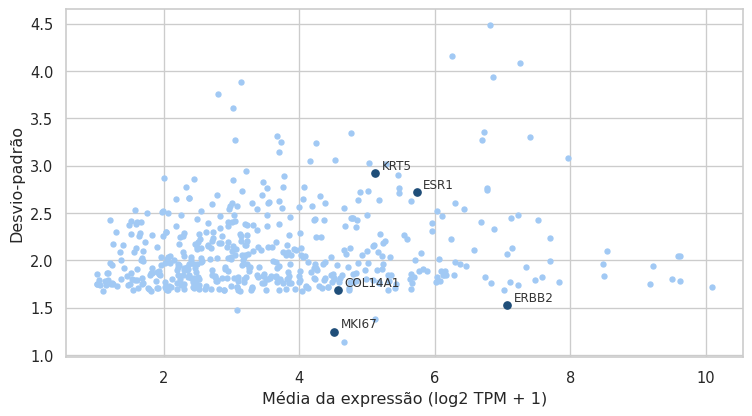

In [5]:
# Média versus desvio-padrão de cada gene, com alguns marcadores em destaque
highlight = ["ESR1", "KRT5", "ERBB2", "MKI67", "COL14A1"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(gene_stats["mean"], gene_stats["std"], color="#A1C9F4", s=14)
ax.scatter(gene_stats.loc[highlight, "mean"], gene_stats.loc[highlight, "std"],
           color="#1F4E79", s=30)
for gene in highlight:
    ax.annotate(gene, gene_stats.loc[gene, ["mean", "std"]], xytext=(5, 3),
                textcoords="offset points", fontsize=9, color="#333333")
ax.set(xlabel="Média da expressão (log2 TPM + 1)", ylabel="Desvio-padrão")
plt.tight_layout()
plt.show()

Tanto a PCA quanto a distância euclidiana ignoram a **média** de cada
atributo: a PCA centraliza cada coluna antes de começar, e somar a mesma
constante a uma coluna não muda a distância entre dois pontos. O que
distorce a geometria é a **dispersão**. Sem padronizar, `KRT5`, com
desvio de 2,92, puxa as distâncias muito mais que `MKI67`, com 1,24,
mesmo que a variação de `MKI67` seja tão informativa quanto a de `KRT5`.

O `StandardScaler` resolve isso: subtrai a média de cada gene e divide
pelo seu desvio-padrão. Cada coluna passa a ter média 0 e desvio 1, e o
valor vira um **escore-z**, que diz a quantos desvios da média do gene
um paciente está.

In [6]:
# Padroniza cada gene para média 0 e desvio-padrão 1
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(expr),
    index=expr.index,
    columns=expr.columns,
)

scaled_check = (
    X_scaled
    .agg(["mean", "std"])
    .T
    .describe()
    .loc[["min", "max"]]
    .round(3)
)

scaled_check

## 2.2 O efeito na PCA

Para ver o efeito da padronização, ajustamos a PCA nos dados brutos e
nos padronizados e comparamos a primeira componente, a PC1. Para cada
versão, listamos a variância que ela explica e os cinco genes com maior
peso (*loading*) em valor absoluto:

In [7]:
# PC1 com e sem padronização: variância explicada e genes de maior peso
pca_by_input = {
    name: PCA(n_components=15, random_state=42).fit(data)
    for name, data in {"sem padronizar": expr, "padronizado": X_scaled}.items()
}

pc1_comparison = pd.DataFrame(
    {
        name: {
            "variância da PC1": f"{model.explained_variance_ratio_[0]:.1%}",
            "genes de maior peso": ", ".join(
                pd.Series(np.abs(model.components_[0]), index=expr.columns)
                .nlargest(5)
                .index
            ),
        }
        for name, model in pca_by_input.items()
    }
).T

pc1_comparison

Sem padronizar, a PC1 explica 20,3% da variância e tem como genes de
maior peso `TFF1`, `AGR3` e `TFF3`, justamente alguns dos genes de maior
desvio-padrão. Padronizada, explica 19,4% e passa a ser liderada por
`FOXA1`, `MLPH` e `ESR1`, genes que variam juntos com muitos outros. A
direção principal mudou pouco, porque os dois trios de genes acompanham
o mesmo eixo de variação, mas a ordem de importância deixou de premiar
quem tem a escala maior.

Neste conjunto, o efeito é modesto porque a seleção dos HVGs já deixou
de fora os genes de variância muito pequena. Em dados tabulares comuns,
com atributos em reais, anos e porcentagens, a diferença costuma ser
drástica. A regra prática vale nos dois casos: antes de qualquer método
baseado em distância ou variância, padronize.

# 3. Redução de dimensionalidade

## 3.1 PCA: o espaço de trabalho

Cada paciente é um ponto em um espaço de 505 dimensões. Há dois motivos
para não agrupar diretamente nesse espaço. O primeiro é que muitos genes
variam juntos, e boa parte das 505 colunas é redundante. O segundo é a
**maldição da dimensionalidade**: em muitas dimensões, as distâncias
entre pontos ficam todas parecidas, e “perto” e “longe” perdem o
contraste de que o K-means depende.

A PCA ajustada com todas as componentes mostra quanto da variância cada
uma acumula:

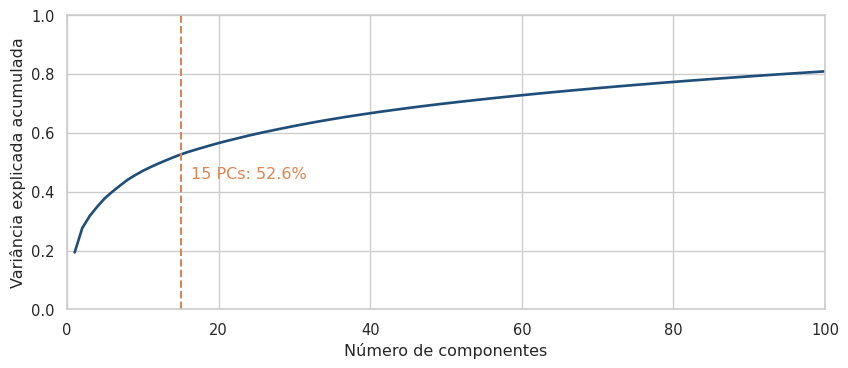

In [8]:
# Variância explicada acumulada por todas as componentes
pca_full = PCA(random_state=42).fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, 101), cumulative_variance[:100], color="#1F4E79", linewidth=2)
ax.axvline(15, color="#DD8452", linestyle="--")
ax.annotate(f"15 PCs: {cumulative_variance[14]:.1%}", (15, cumulative_variance[14]),
            xytext=(8, -18), textcoords="offset points", color="#DD8452")
ax.set(xlabel="Número de componentes", ylabel="Variância explicada acumulada",
       xlim=(0, 100), ylim=(0, 1))
plt.tight_layout()
plt.show()

A curva sobe rápido nas primeiras componentes e depois se arrasta. As 15
primeiras explicam 52,6% da variância, e seriam necessárias 95 para
chegar a 80%. Ficamos com 15: elas guardam a estrutura de grande escala,
compartilhada por muitos genes, e deixam de fora uma longa cauda de
componentes que capturam, cada uma, menos de 1% da variância e são em
boa parte ruído.

In [9]:
# Projeta os pacientes nas 15 primeiras componentes principais
pca = PCA(n_components=15, random_state=42)
X_pca = pca.fit_transform(X_scaled)

X_pca.shape

(1095, 15)

Para ver a maldição da dimensionalidade em números, comparamos a
dispersão das distâncias entre todos os pares de pacientes nos 505 genes
padronizados, nas 15 componentes e em uma tabela de ruído puro do mesmo
tamanho. A medida é o coeficiente de variação das distâncias, o
desvio-padrão dividido pela média: quanto menor, mais parecidas são
todas as distâncias.

In [10]:
# Contraste das distâncias entre pares de pacientes em três espaços
rng = np.random.default_rng(42)
spaces = {
    "505 genes padronizados": X_scaled,
    "15 componentes principais": X_pca,
    "ruído puro (505 colunas)": rng.normal(size=X_scaled.shape),
}

pair_distances = {
    name: pairwise_distances(data)[np.triu_indices(len(data), k=1)]
    for name, data in spaces.items()
}

distance_contrast = (
    pd.Series(pair_distances)
    .map(lambda d: d.std() / d.mean())
    .round(3)
    .rename("CV das distâncias")
    .to_frame()
)

distance_contrast

No ruído puro, todas as distâncias ficam praticamente iguais (CV de
0,031): nenhum ponto está de fato mais perto de outro. Os genes reais
têm estrutura, e o contraste é cinco vezes maior (0,156). Nas 15
componentes, quase dobra (0,284). A PCA descartou dimensões que só
somavam ruído às distâncias, e é nesse espaço que o K-means vai
trabalhar.

## 3.2 UMAP: o espaço de visualização

Quinze dimensões ainda não cabem em um gráfico. Poderíamos plotar só a
PC1 contra a PC2, mas elas resumem pouco mais de um quarto da variância.
O **UMAP** (*Uniform Manifold Approximation and Projection*) é um método
não linear que constrói um grafo de vizinhos no espaço original e
procura uma disposição em 2D que preserve esses vizinhos. Aplicamos o
UMAP às 15 componentes:

In [11]:
# Projeta as 15 componentes em 2D com o UMAP, apenas para visualização
umap_model = UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = pd.DataFrame(
    umap_model.fit_transform(X_pca),
    index=expr.index,
    columns=["UMAP1", "UMAP2"],
)

embedding.head()

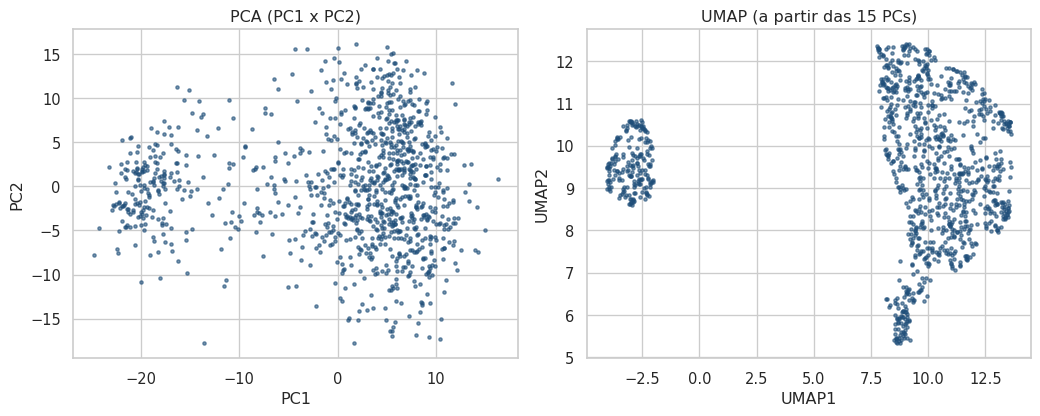

In [12]:
# Os mesmos pacientes no plano PC1 x PC2 e no plano do UMAP
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], color="#1F4E79", s=6, alpha=0.6)
axes[0].set(title="PCA (PC1 x PC2)", xlabel="PC1", ylabel="PC2")
axes[1].scatter(embedding["UMAP1"], embedding["UMAP2"], color="#1F4E79", s=6, alpha=0.6)
axes[1].set(title="UMAP (a partir das 15 PCs)", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

No plano PC1 x PC2 já se vê um grupo separado à esquerda e uma nuvem
maior à direita. O UMAP deixa essa separação mais nítida e sugere
subdivisões dentro da nuvem.

O UMAP tem um preço. Ele preserva quem é vizinho de quem, mas distorce
todo o resto: o tamanho aparente de um grupo e a distância entre dois
grupos no gráfico não têm significado quantitativo. Por isso, a divisão
de trabalho desta aula é rígida. A PCA é o espaço de trabalho, onde se
calculam distâncias e se ajusta o K-means. O UMAP é só a tela onde
desenhamos os resultados.

# 4. Agrupamento com K-means

## 4.1 Como o K-means funciona

O **K-means** divide as amostras em $k$ grupos, cada um representado por
um **centroide**, o ponto médio do grupo. O algoritmo alterna dois
passos até que nada mude:

1.  Atribuir cada amostra ao centroide mais próximo.
2.  Mover cada centroide para a média das amostras atribuídas a ele.

O critério que esses passos reduzem a cada rodada é a **inércia**, a
soma das distâncias quadráticas de cada amostra ao seu centroide:

$$
\text{inércia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2,
$$

em que $\mu_{c(i)}$ é o centroide do grupo da amostra $i$. É o mesmo
espírito dos mínimos quadrados, agora sem uma resposta $y$: o K-means
busca os centros que deixam os resíduos, as distâncias de cada ponto ao
seu centro, os menores possíveis. Como o resultado depende dos
centroides iniciais, sorteados, o scikit-learn repete o algoritmo
`n_init` vezes e fica com a solução de menor inércia.

## 4.2 Escolhendo $k$

O K-means não descobre quantos grupos existem: $k$ é um hiperparâmetro.
Rodamos o algoritmo de $k = 2$ a $k = 8$ e registramos duas medidas. A
inércia sempre cai quando $k$ aumenta, porque, com mais centroides, cada
ponto tende a ter um deles mais perto. A **silhueta** compara, para cada
amostra, a distância média aos membros do próprio grupo ($a$) com a
distância média aos membros do grupo vizinho mais próximo ($b$):

$$
s = \frac{b - a}{\max(a, b)}.
$$

Ela vai de $-1$ a $1$. Valores perto de 1 indicam uma amostra bem dentro
do seu grupo e longe do vizinho; perto de 0, uma amostra na fronteira. A
silhueta da partição é a média sobre todas as amostras.

In [13]:
# Inércia e silhueta para k de 2 a 8, no espaço das 15 componentes
k_values = range(2, 9)
kmeans_by_k = {
    k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    for k in k_values
}

k_selection = pd.DataFrame(
    {
        "inércia": [model.inertia_ for model in kmeans_by_k.values()],
        "silhueta": [
            silhouette_score(X_pca, model.labels_) for model in kmeans_by_k.values()
        ],
    },
    index=pd.Index(k_values, name="k"),
).round(3)

k_selection

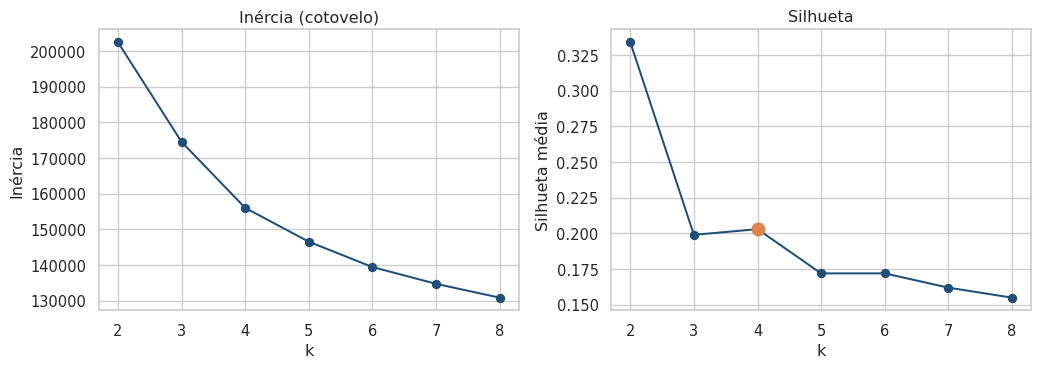

In [14]:
# Curvas de inércia e silhueta em função de k
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_selection.index, k_selection["inércia"], marker="o", color="#1F4E79")
axes[0].set(xlabel="k", ylabel="Inércia", title="Inércia (cotovelo)")
axes[1].plot(k_selection.index, k_selection["silhueta"], marker="o", color="#1F4E79")
axes[1].scatter(4, k_selection.loc[4, "silhueta"], color="#DD8452", s=90, zorder=3)
axes[1].set(xlabel="k", ylabel="Silhueta média", title="Silhueta")
plt.tight_layout()
plt.show()

A silhueta é máxima em $k = 2$ (0,334). Essa é a divisão mais nítida dos
dados: o grupo isolado à esquerda do UMAP contra todo o resto. Depois
cai para 0,199 em $k = 3$, sobe a um pico secundário de 0,203 em $k = 4$
e volta a cair. A curva de inércia não tem um cotovelo marcado, mas a
queda perde força a partir de $k = 4$.

Escolher $k$ é uma decisão de quem analisa, apoiada nessas medidas e no
uso que se vai fazer dos grupos. Com $k = 2$, teríamos a partição mais
limpa e também a menos informativa. Ficamos com $k = 4$, o pico
secundário da silhueta, que divide a nuvem grande sem fragmentá-la em
grupos que a silhueta já não sustenta. Em agrupamento não existe a
resposta certa que havia na regressão, e a validação será, em parte, dar
nome aos grupos e ver se eles fazem sentido.

## 4.3 O modelo com $k = 4$

In [15]:
# K-means com k = 4 e o tamanho de cada grupo
kmeans = kmeans_by_k[4]
clusters = pd.Series(kmeans.labels_, index=expr.index, name="cluster")

cluster_sizes = clusters.value_counts().sort_index()

cluster_sizes

cluster
0    181
1    374
2    346
3    194
Name: count, dtype: int64

Os quatro grupos têm 181, 374, 346 e 194 pacientes. Os números de 0 a 3
são apenas identificadores, sem ordem nem significado. Rodar de novo com
outro `random_state` poderia trocar os números entre os grupos sem mudar
a partição.

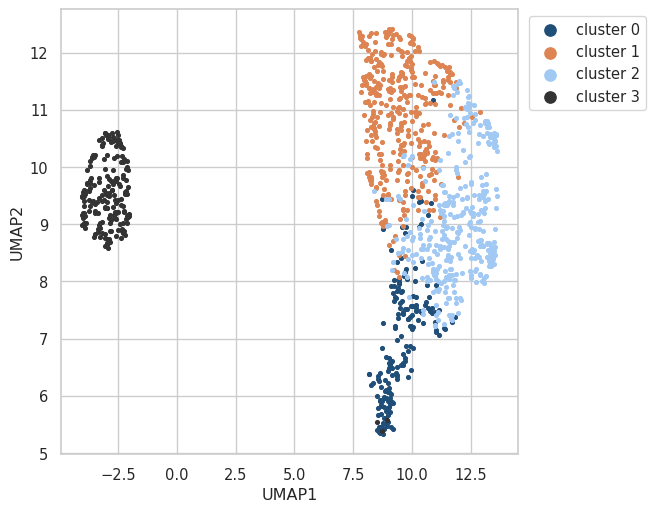

In [16]:
# UMAP colorido pelo identificador bruto do cluster
cluster_colors = {0: "#1F4E79", 1: "#DD8452", 2: "#A1C9F4", 3: "#333333"}

fig, ax = plt.subplots(figsize=(7, 5.5))
for cluster_id, color in cluster_colors.items():
    members = embedding[clusters == cluster_id]
    ax.scatter(members["UMAP1"], members["UMAP2"], color=color, s=8,
               label=f"cluster {cluster_id}")
ax.set(xlabel="UMAP1", ylabel="UMAP2")
ax.legend(markerscale=3, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Os grupos foram calculados nas 15 componentes, sem nenhuma informação do
UMAP, e mesmo assim ocupam regiões contíguas no gráfico. O cluster
isolado à esquerda corresponde ao grupo que a silhueta já separava em
$k = 2$. Os outros três dividem a nuvem maior, com fronteiras que se
tocam. Agora precisamos descobrir o que cada um representa.

# 5. Dando nome aos clusters

Um cluster é só uma lista de pacientes. Para torná-lo útil, precisamos
saber o que o distingue dos demais. Usamos três técnicas, nenhuma das
quais exige conhecer a biologia.

## 5.1 Atributos discriminantes

A primeira é olhar, em cada cluster, a média do escore-z de cada gene.
Como cada gene tem média 0 no conjunto todo, uma média de $+1$ em um
cluster quer dizer que, ali, o gene está em média um desvio-padrão acima
do habitual. Os cinco genes de maior escore-z médio em cada cluster:

In [17]:
# Escore-z médio de cada gene dentro de cada cluster
cluster_zscores = X_scaled.groupby(clusters).mean()

top_genes = pd.DataFrame(
    {
        f"cluster {cluster_id}": row.nlargest(5).index
        for cluster_id, row in cluster_zscores.iterrows()
    },
    index=pd.RangeIndex(1, 6, name="posição"),
)

top_genes

Cada cluster tem o seu conjunto próprio de genes em alta. Os do cluster
3 têm escore-z médio acima de 1,5, o maior de todos, coerente com o
grupo mais isolado no UMAP.

Esse ranking tem duas limitações. Ele compara cada cluster com a média
geral, um de cada vez, e olha só para as médias. Um gene pode ter média
alta em um cluster porque alguns poucos pacientes têm valores extremos,
enquanto os outros pacientes do mesmo cluster se espalham por toda a
escala. Para medir quanto um gene separa os quatro grupos ao mesmo
tempo, levando em conta essa dispersão interna, usamos a ANOVA.

### A ANOVA como régua de separação

A **ANOVA de um fator** é o teste clássico para comparar as médias de
três ou mais grupos. A hipótese nula é que todos os grupos têm a mesma
média. Para um gene, a ANOVA divide a variação total da expressão em
duas partes. A **soma de quadrados entre grupos** ($SQG$) mede quanto as
médias dos clusters se afastam da média geral. A **soma de quadrados
dentro dos grupos** ($SQR$, de resíduos) mede quanto os pacientes se
espalham em torno da média do próprio cluster:

$$
SQG = \sum_{g=1}^{k} n_g (\bar{x}_g - \bar{x})^2,
\qquad
SQR = \sum_{g=1}^{k} \sum_{i \in g} (x_i - \bar{x}_g)^2,
$$

em que $k$ é o número de grupos, $n_g$ e $\bar{x}_g$ são o tamanho e a
média do grupo $g$, e $\bar{x}$ é a média geral. A estatística $F$
compara as duas partes, cada uma dividida pelos seus graus de liberdade:

$$
F = \frac{SQG / (k - 1)}{SQR / (N - k)}.
$$

Com $N = 1.095$ pacientes e $k = 4$ clusters, os graus de liberdade são
3 e 1.091. Se os clusters não diferissem nesse gene, as médias dos
grupos oscilariam só por acaso, e $F$ ficaria perto de 1. Quanto mais as
médias se afastam umas das outras em relação à variação dentro de cada
grupo, maior o $F$.

No aprendizado de máquina, essa mesma conta é uma ferramenta de
**seleção de atributos**. O scikit-learn a oferece como `f_classif`, que
roda uma ANOVA para cada coluna de `X` usando as classes de `y` como
grupos. Em um problema supervisionado, ela costuma ser usada para reter
os atributos que mais separam as classes antes de treinar um modelo.
Aqui não temos classes, então usamos os identificadores dos clusters no
papel de `y`:

In [18]:
# Estatística F e p-valor da ANOVA de cada gene, com os clusters como grupos
f_statistic, p_values = f_classif(expr, clusters)
f_scores = pd.Series(f_statistic, index=expr.columns, name="F")

anova_ranking = (
    f_scores
    .nlargest(10)
    .round(0)
    .to_frame()
)

anova_ranking

`FOXA1` e `MLPH` lideram o ranking. Os dois têm expressão média entre
6,7 e 8,4 nos clusters 0, 1 e 2 e abaixo de 2,6 no cluster 3, e separam
esse grupo de todos os outros. `FOXC1`, o quarto, faz o mesmo na direção
oposta: é o primeiro gene do cluster 3. Já `ESR1`, o quinto, varia
também entre os clusters da nuvem maior, mais baixo no cluster 0 (4,3)
que nos clusters 1 e 2 (6,8 e 7,7).

Para ver o que o $F$ mede, comparamos o gene de maior $F$ com o de menor
$F$ entre os 505:

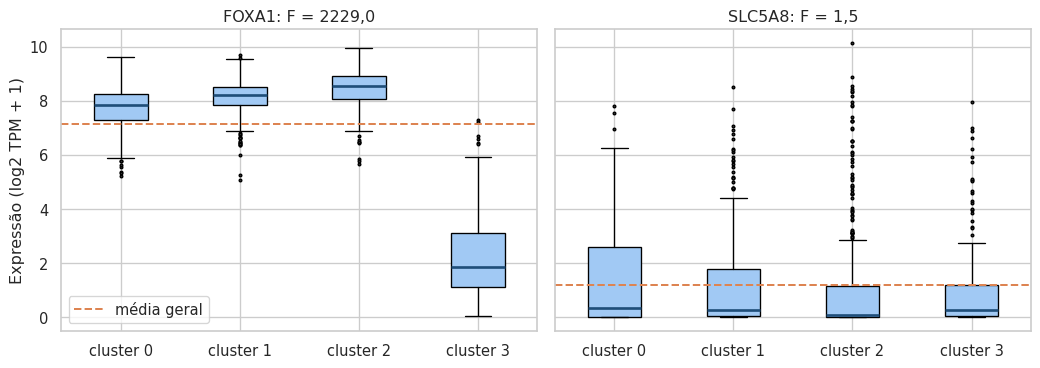

In [19]:
# Expressão por cluster do gene de maior F e do gene de menor F
contrast_genes = [f_scores.idxmax(), f_scores.idxmin()]
cluster_ids = sorted(clusters.unique())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, gene in zip(axes, contrast_genes):
    groups = [expr.loc[clusters == cluster_id, gene] for cluster_id in cluster_ids]
    ax.boxplot(groups, tick_labels=[f"cluster {c}" for c in cluster_ids],
               patch_artist=True, boxprops={"facecolor": "#A1C9F4"},
               medianprops={"color": "#1F4E79", "linewidth": 2},
               flierprops={"markersize": 2, "markerfacecolor": "#333333"})
    ax.axhline(expr[gene].mean(), color="#DD8452", linestyle="--",
               label="média geral")
    ax.set(title=f"{gene}: F = {f_scores[gene]:.1f}".replace(".", ","))
axes[0].set(ylabel="Expressão (log2 TPM + 1)")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

À esquerda, as caixas de `FOXA1` ficam bem afastadas da média geral, a
linha tracejada: as dos clusters 0, 1 e 2 estão acima dela, estreitas e
quase sem sobreposição com a do cluster 3, que fica muito abaixo. Quase
toda a variação desse gene está entre os grupos. A fração da variação
total explicada pelos clusters, $\eta^2 = SQG / (SQG + SQR)$, é de cerca
de 0,86. À direita, `SLC5A8` tem quatro distribuições quase iguais:
medianas perto de zero, caixas sobrepostas e, em todos os clusters,
alguns pacientes com expressão alta. O gene varia muito entre pacientes,
e por isso está entre os HVGs, mas essa variação não acompanha os
clusters. O seu $F$ fica perto de 1.

### Por que não ler os $p$-valores

A ANOVA também devolve um $p$-valor por gene. É tentador usá-lo para
dizer quais genes diferem “significativamente” entre os clusters:

In [20]:
# Quantos genes seriam "significantes" pela ANOVA
significant_genes = pd.Series(
    {
        "p < 0,05": (p_values < 0.05).sum(),
        "p < 1e-10": (p_values < 1e-10).sum(),
        "total de genes": len(p_values),
    },
    name="genes",
)

significant_genes

p < 0,05          501
p < 1e-10         472
total de genes    505
Name: genes, dtype: int64

Dos 505 genes, 501 têm $p < 0{,}05$, e 472 têm $p$ menor que um em dez
bilhões. Esses números não descobrem nada. O K-means escolheu os grupos
justamente para que eles fossem o mais diferentes possível nesses mesmos
genes, e testar em seguida se os grupos diferem é perguntar aos dados
algo que já obrigamos os dados a responder. A hipótese nula, de médias
iguais, nunca teve chance. Esse erro é conhecido como *double dipping*,
usar os mesmos dados para formar uma hipótese e para testá-la. O
$p$-valor só teria o seu significado usual se os grupos viessem de fora,
por exemplo, de um diagnóstico clínico.

Por isso, nesta aula, a ANOVA não é um teste de hipótese. A estatística
$F$ é só uma régua para ordenar os genes pelo quanto separam os
clusters.

## 5.2 Tradução pelo dicionário

Com os genes de cada cluster em mãos, entra o dicionário. Em vez de
procurar os marcadores um a um nas listas de cinco, calculamos para cada
cluster um **escore de assinatura**: a média dos escores-z médios dos
genes de cada perfil. Assim, todo o dicionário é comparado com todos os
clusters de uma vez:

In [21]:
# Escore de assinatura: média do escore-z dos genes de cada perfil, por cluster
signature_scores = pd.DataFrame(
    {profile: cluster_zscores[genes].mean(axis=1) for profile, genes in markers.items()}
).rename_axis("cluster")

signature_scores.round(2)

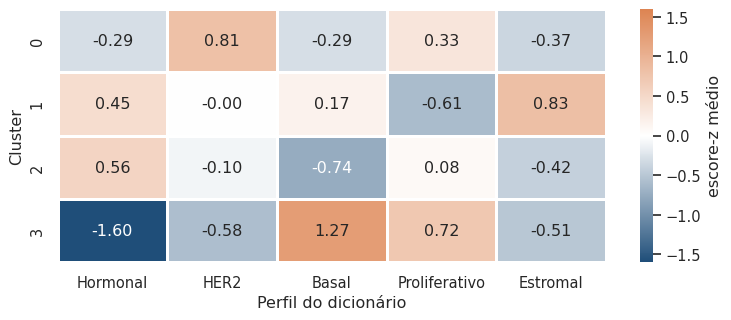

In [22]:
# Mapa de calor dos escores de assinatura
diverging = LinearSegmentedColormap.from_list(
    "diverging", ["#1F4E79", "#FFFFFF", "#DD8452"]
)

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(signature_scores, cmap=diverging, center=0, vmin=-1.6, vmax=1.6,
            annot=True, fmt=".2f", linewidths=1,
            cbar_kws={"label": "escore-z médio"}, ax=ax)
ax.set(xlabel="Perfil do dicionário", ylabel="Cluster")
plt.tight_layout()
plt.show()

Cada cluster tem um perfil que se destaca: o 0 é HER2 (0,81), o 1 é
Estromal (0,83), o 2 é Hormonal (0,56) e o 3 é Basal (1,27), com o
Hormonal em $-1{,}60$, o valor mais negativo da tabela. O nome de cada
cluster é o perfil de maior escore na sua linha:

In [23]:
# Rótulo de cada cluster: o perfil de maior escore de assinatura
cluster_names = signature_scores.idxmax(axis=1)
labels = clusters.map(cluster_names).rename("rotulo")

label_sizes = labels.value_counts()

label_sizes

rotulo
Estromal    374
Hormonal    346
Basal       194
HER2        181
Name: count, dtype: int64

O perfil Proliferativo não deu nome a nenhum cluster. O seu escore é
mais alto no Basal (0,72) e no HER2 (0,33) e está perto de zero no
Hormonal (0,08). A proliferação não forma um grupo próprio nestes dados:
ela é um gradiente que atravessa os grupos. Já o grupo Estromal é
formado por amostras com muito tecido de sustentação ao redor do tumor,
e o K-means o separou porque essa mistura muda a expressão de muitos
genes ao mesmo tempo. O algoritmo encontra a estrutura de maior
variância, que nem sempre é a que esperávamos encontrar. O dicionário
serve para traduzir o que foi achado, não para forçar o que deveria ser
achado.

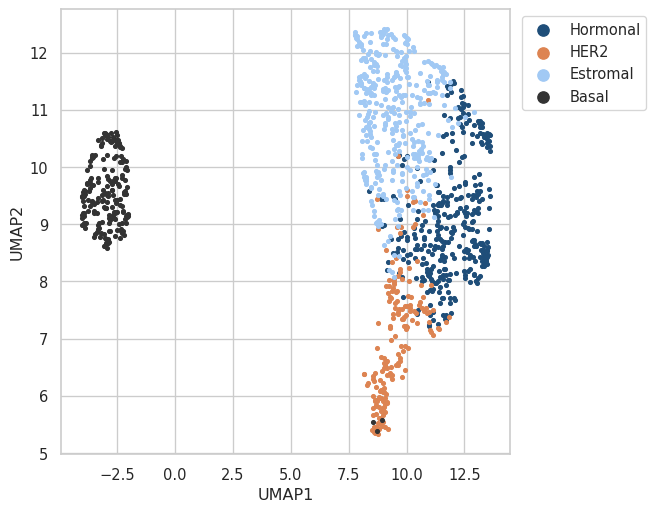

In [24]:
# UMAP colorido pelos rótulos
label_colors = {
    "Hormonal": "#1F4E79",
    "HER2": "#DD8452",
    "Estromal": "#A1C9F4",
    "Basal": "#333333",
}

fig, ax = plt.subplots(figsize=(7, 5.5))
for label, color in label_colors.items():
    members = embedding[labels == label]
    ax.scatter(members["UMAP1"], members["UMAP2"], color=color, s=8, label=label)
ax.set(xlabel="UMAP1", ylabel="UMAP2")
ax.legend(markerscale=3, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 5.3 Uma árvore de decisão substituta

A terceira técnica dispensa qualquer dicionário. Treinamos uma árvore de
decisão rasa para prever o rótulo de cada paciente a partir da expressão
original dos 505 genes. A árvore não tem a pretensão de prever pacientes
novos. Ela é um **modelo substituto** (*surrogate model*): um modelo
simples, que imita o K-means e cujas regras podemos ler.

In [25]:
# Árvore de decisão de profundidade 3 imitando a partição do K-means
surrogate_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(expr, labels)
fidelity = surrogate_tree.score(expr, labels)

round(fidelity, 3)

0.829

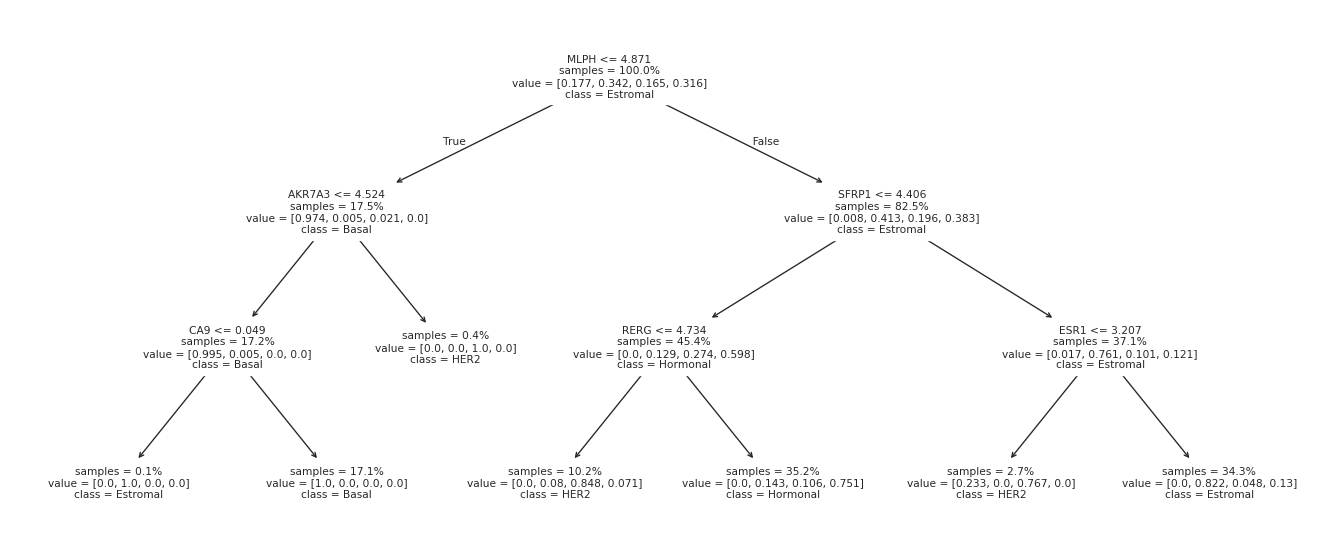

In [26]:
# Regras da árvore substituta
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(surrogate_tree, feature_names=expr.columns, class_names=surrogate_tree.classes_,
          filled=False, impurity=False, proportion=True, fontsize=8, ax=ax)
plt.tight_layout()
plt.show()

Com só três perguntas por paciente, a árvore reproduz o rótulo do
K-means em 82,9% dos casos. Ela escolheu os genes sozinha, e quase
nenhum deles está no dicionário. A primeira pergunta é `MLPH <= 4.871`.
`MLPH` é o segundo gene do ranking da ANOVA, e o ramo de expressão baixa
reúne 17,5% dos pacientes, 97,4% deles do grupo Basal. No ramo de
expressão alta, `SFRP1` separa o Estromal, com valores altos, do
Hormonal e do HER2, e `RERG` separa esses dois. O próprio `ESR1` aparece
no último nível, retirando do ramo Estromal um pequeno grupo de tumores
HER2.

As regras dão uma descrição alternativa de cada grupo: o cluster
Hormonal, por exemplo, é “`MLPH` alto, `SFRP1` baixo e `RERG` alto”. Uma
árvore mais profunda seria mais fiel e mais difícil de ler. A
profundidade 3 é um compromisso entre fidelidade e legibilidade.

# 6. Dos clusters ao classificador

Os rótulos estão prontos, e com eles poderíamos treinar um classificador
supervisionado para atribuir um grupo a um paciente novo sem rodar o
K-means outra vez. Antes, há um problema. O K-means é categórico: um
paciente exatamente na fronteira entre dois centroides recebe um rótulo
com a mesma convicção de um paciente no centro do grupo. Se treinarmos
com rótulos duvidosos, o classificador aprende fronteiras igualmente
duvidosas.

## 6.1 Uma margem de confiança

O método `.transform` do K-means devolve a distância de cada paciente a
cada um dos quatro centroides. Para cada paciente, comparamos a
distância ao centroide vencedor, $d_1$, com a distância ao segundo mais
próximo, $d_2$:

$$
\text{razão} = \frac{d_1}{d_2}.
$$

A razão vai de 0, para um paciente sobre o próprio centroide, a 1, para
um paciente equidistante dos dois centroides mais próximos. Adotamos um
corte de 0,75: abaixo dele, o rótulo é **confiável**; acima, o paciente
é **ambíguo**.

In [27]:
# Razão entre a distância ao centroide mais próximo e ao segundo mais próximo
centroid_distances = np.sort(kmeans.transform(X_pca), axis=1)
distance_ratio = pd.Series(
    centroid_distances[:, 0] / centroid_distances[:, 1],
    index=expr.index,
    name="razao",
)
confident = distance_ratio < 0.75

confident.value_counts()

razao
True     642
False    453
Name: count, dtype: int64

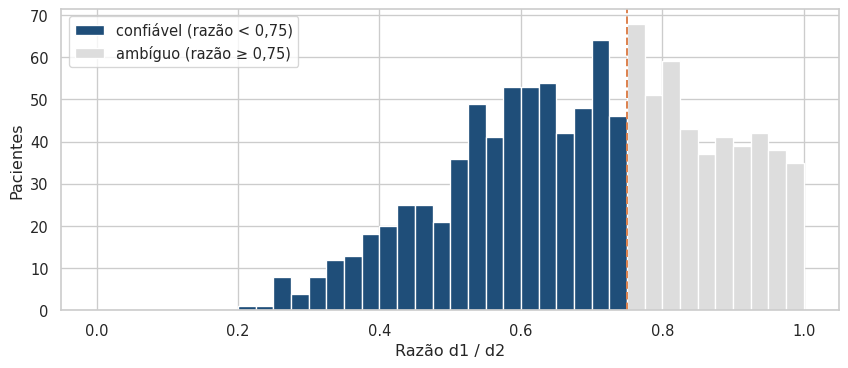

In [28]:
# Distribuição da razão de distâncias, com o corte de 0,75
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(distance_ratio[confident], bins=np.arange(0, 1.02, 0.025), color="#1F4E79",
        label="confiável (razão < 0,75)")
ax.hist(distance_ratio[~confident], bins=np.arange(0, 1.02, 0.025), color="#DDDDDD",
        label="ambíguo (razão ≥ 0,75)")
ax.axvline(0.75, color="#DD8452", linestyle="--")
ax.set(xlabel="Razão d1 / d2", ylabel="Pacientes")
ax.legend()
plt.tight_layout()
plt.show()

Dos 1.095 pacientes, 642 têm rótulo confiável e 453 ficam como ambíguos.
A distribuição não tem um vale natural entre os dois tipos. O pico fica
logo abaixo do corte, e centenas de pacientes têm razão acima de 0,8,
quase equidistantes de dois centroides: os grupos se tocam, como o UMAP
já mostrava. O corte de 0,75 é uma escolha, como $k$. Um corte mais
baixo deixa os rótulos mais limpos e o conjunto de treino menor.

In [29]:
# Pacientes confiáveis e ambíguos em cada rótulo
confidence_by_label = (
    pd.crosstab(labels, confident.map({True: "confiável", False: "ambíguo"}))
    .assign(
        fracao_confiavel=lambda df: (df["confiável"] / df.sum(axis=1)).round(2)
    )
)

confidence_by_label

O grupo Basal, o mais isolado, tem 95% dos pacientes com rótulo
confiável. Nos três grupos que dividem a nuvem maior, a fração fica
entre 47% e 56%: cerca de metade dos pacientes está perto de alguma
fronteira.

## 6.2 Treinando o classificador

Esses rótulos criados pelo próprio modelo, e não por um especialista,
são **pseudo-rótulos** (*pseudo-labels*). Com eles, treinamos uma
floresta aleatória (`RandomForestClassifier`) usando como atributos a
expressão original dos 505 genes e, como resposta, os rótulos dos 642
pacientes confiáveis. A floresta combina centenas de árvores de decisão
como a do modelo substituto, Cada árvore é treinada em uma reamostragem
diferente dos pacientes e, a cada divisão, escolhe entre um sorteio de
genes. A floresta decide pela votação de todas as árvores. Antes de
usá-la, medimos o seu desempenho com validação cruzada estratificada de
5 dobras:

In [30]:
# Validação cruzada da floresta aleatória nos pacientes confiáveis
X_confident = expr[confident]
y_confident = labels[confident]

forest = RandomForestClassifier(n_estimators=500, random_state=42)
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_accuracy = cross_val_score(forest, X_confident, y_confident, cv=skfold,
                              scoring="accuracy")

cv_accuracy.round(3)

array([1.   , 0.984, 0.984, 1.   , 0.977])

A acurácia média é de 98,9%. Esse número parece bom demais, e é. Os
pacientes confiáveis foram escolhidos justamente por estarem longe das
fronteiras, e as fronteiras são onde um classificador erra. Os rótulos
também vieram dos mesmos genes que agora servem de atributos. A
validação cruzada confirma que a floresta reproduz o K-means nos casos
fáceis, mas não diz nada sobre como ela se sai nos difíceis.

## 6.3 Prevendo os pacientes ambíguos

Ajustamos a floresta em todos os pacientes confiáveis e pedimos a ela um
rótulo para cada paciente ambíguo. Além da classe prevista,
`predict_proba` devolve, para cada classe, a média das probabilidades
atribuídas pelas árvores. Como cada árvore cresce até folhas quase
puras, esse valor é praticamente a fração de árvores que votou na
classe, e o maior deles funciona como uma medida da confiança da
previsão:

In [31]:
# Ajuste final nos confiáveis e previsão dos ambíguos
forest.fit(X_confident, y_confident)
X_ambiguous = expr[~confident]

ambiguous_predictions = pd.DataFrame(
    {
        "kmeans": labels[~confident],
        "floresta": forest.predict(X_ambiguous),
        "probabilidade": forest.predict_proba(X_ambiguous).max(axis=1),
    },
    index=X_ambiguous.index,
)

ambiguous_predictions.head()

In [32]:
# Concordância com o K-means e resumo das probabilidades nos ambíguos
agreement = ambiguous_predictions["kmeans"] == ambiguous_predictions["floresta"]
probabilities = ambiguous_predictions["probabilidade"]

ambiguous_summary = pd.Series(
    {
        "concordância com o K-means": agreement.mean(),
        "probabilidade mediana": probabilities.median(),
        "fração com probabilidade < 0,5": (probabilities < 0.5).mean(),
    }
).round(3)

ambiguous_summary

concordância com o K-means        0.770
probabilidade mediana             0.600
fração com probabilidade < 0,5    0.265
dtype: float64

Nos 453 pacientes ambíguos, a floresta concorda com o K-means em 77,0%
dos casos. Nos outros 23,0%, ela discorda, e isso não é necessariamente
um erro: o K-means decide pela distância nas 15 componentes, enquanto a
floresta aprendeu regras nos 505 genes a partir dos casos típicos de
cada grupo. A probabilidade mediana é de 0,60, e em 26,5% dos ambíguos
nenhuma classe recebe metade dos votos. O classificador não esconde a
dúvida. Em um paciente ambíguo, uma probabilidade de 0,45 para HER2 e
0,40 para Hormonal informa mais que um rótulo seco.

Juntamos os rótulos confiáveis do K-means às previsões da floresta para
os ambíguos. Para o gráfico, cada ponto recebe também uma opacidade: 1
para os confiáveis e a probabilidade prevista para os ambíguos.

In [33]:
# Rótulo final e opacidade de cada paciente
final_labels = labels.where(confident, ambiguous_predictions["floresta"])
point_alpha = (
    pd.Series(1.0, index=expr.index)
    .where(confident, ambiguous_predictions["probabilidade"])
)

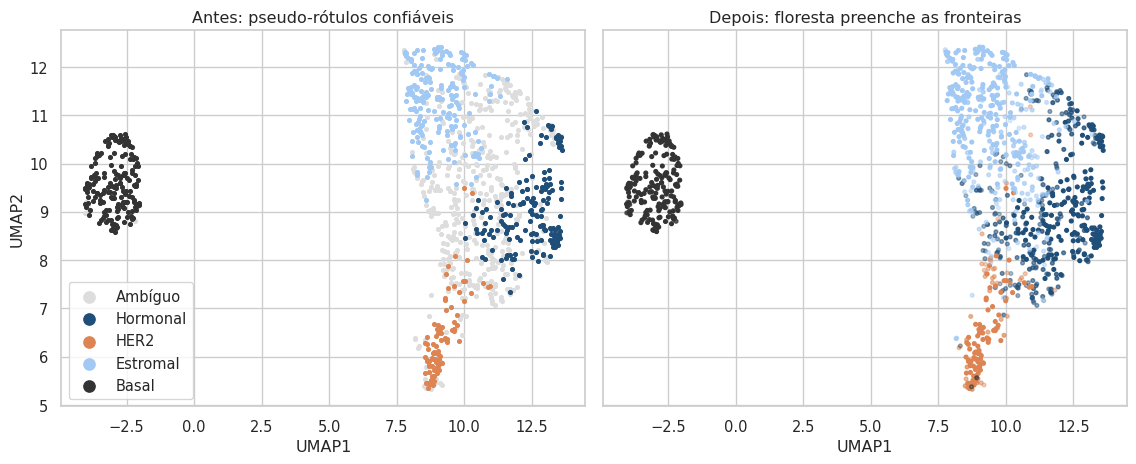

In [34]:
# UMAP antes (clusters com ambíguos em cinza) e depois (previsões da floresta)
label_colors = {
    "Hormonal": "#1F4E79",
    "HER2": "#DD8452",
    "Estromal": "#A1C9F4",
    "Basal": "#333333",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
ambiguous_points = embedding[~confident]
axes[0].scatter(ambiguous_points["UMAP1"], ambiguous_points["UMAP2"],
                color="#DDDDDD", s=8, label="Ambíguo")
for label, color in label_colors.items():
    members = embedding[confident & (labels == label)]
    axes[0].scatter(members["UMAP1"], members["UMAP2"], color=color, s=8, label=label)
    predicted = final_labels == label
    axes[1].scatter(embedding.loc[predicted, "UMAP1"], embedding.loc[predicted, "UMAP2"],
                    color=color, s=8, alpha=point_alpha[predicted], label=label)
axes[0].set(title="Antes: pseudo-rótulos confiáveis", xlabel="UMAP1", ylabel="UMAP2")
axes[1].set(title="Depois: floresta preenche as fronteiras", xlabel="UMAP1")
axes[0].legend(markerscale=3, loc="lower left")
plt.tight_layout()
plt.show()

À esquerda, os núcleos dos grupos estão coloridos e as fronteiras, em
cinza. À direita, a floresta preenche as fronteiras, e os pontos mais
apagados, os de menor probabilidade, se concentram onde dois grupos se
encontram. O ciclo está completo: uma tabela sem nenhum rótulo virou um
classificador que atribui um grupo, com uma medida de confiança, a
qualquer paciente novo cuja expressão seja medida nos mesmos 505 genes.

# 7. Os rótulos batem com a classificação oficial?

Até aqui, nenhum rótulo externo entrou na análise. Mas, para estes
tumores, existe uma classificação de referência, o **PAM50**, que
atribui a cada tumor um de cinco subtipos moleculares. Ela foi
construída por especialistas a partir de anos de estudos de expressão
gênica em tumores de mama. Só agora, com tudo pronto, comparamos as duas
classificações:

In [35]:
# Classificação PAM50 oficial, disponível para parte dos pacientes
pam50 = (
    pd.read_csv("tcga-brca/data/brca_pam50.csv", index_col="paciente")["pam50"]
    .dropna()
)

pam50_comparison = pd.crosstab(final_labels.loc[pam50.index], pam50)

pam50_comparison

O PAM50 está disponível para 842 dos 1.095 pacientes. O grupo Basal
reúne 135 dos 139 tumores Basal do PAM50, uma correspondência quase
perfeita. O grupo HER2 reúne 62 dos 67 tumores Her2 do PAM50, mas também
13 LumA e 26 LumB. Hormonal e Estromal dividem os tumores luminais: o
Estromal é quase todo LumA (240 de 272), e o Hormonal mistura LumA e
LumB em proporções parecidas (168 e 150).

O **índice de Rand ajustado** (ARI) resume a concordância entre duas
partições. Ele vale 1 quando elas coincidem e fica perto de 0 quando a
concordância não passa do que o acaso produziria, sem se importar com os
nomes dos grupos:

In [36]:
# Índice de Rand ajustado entre a partição final e o PAM50
ari = adjusted_rand_score(pam50, final_labels.loc[pam50.index])

round(ari, 3)

0.399

Um ARI de 0,40 indica uma concordância moderada, bem acima do acaso e
bem abaixo da coincidência. O resultado é bom, considerando que o PAM50
usa genes escolhidos a dedo e o nosso K-means não recebeu nenhuma
orientação. A divergência também é informativa. A partição mais forte
nestes dados separa os tumores pela quantidade de tecido normal ao redor
deles (o grupo Estromal) antes de separá-los pela proliferação (LumA
contra LumB). Um algoritmo não supervisionado responde à pergunta “qual
é a estrutura de maior variância?”, e essa nem sempre é a pergunta que o
especialista faria.

# Síntese

-   Métodos geométricos, como a PCA e o K-means, dependem da escala dos
    atributos. A média não interfere, mas a dispersão sim, e o
    `StandardScaler` coloca todos os atributos com o mesmo peso.
-   A PCA reduz 505 atributos a 15 componentes que guardam a estrutura
    compartilhada e descartam ruído, devolvendo contraste às distâncias.
    É o espaço de trabalho.
-   O UMAP projeta as componentes em 2D preservando vizinhanças, mas
    distorce tamanhos e distâncias entre grupos. É só o espaço de
    visualização.
-   O K-means particiona as amostras em torno de $k$ centroides,
    minimizando a inércia. O valor de $k$ é escolhido com a inércia, a
    silhueta e o propósito da análise.
-   Dar nome a um cluster é um problema de seleção de atributos:
    escore-z médio, ANOVA, escores de assinatura de um dicionário e uma
    árvore substituta legível.
-   A razão $d_1 / d_2$ separa pseudo-rótulos confiáveis de ambíguos. Um
    classificador treinado nos confiáveis rotula os ambíguos com uma
    probabilidade, completando o ciclo do não supervisionado ao
    supervisionado.
-   Uma classificação externa, quando existe, valida a partição pelo
    ARI. As divergências mostram que o algoritmo encontra a estrutura de
    maior variância, que pode não ser a esperada.

# Perguntas para consolidar

1.  Se, em vez de padronizar, apenas centralizássemos cada gene
    (subtraindo a média sem dividir pelo desvio-padrão), o resultado do
    K-means mudaria em relação aos dados brutos?

> **Como pensar sobre isso**
>
> Não. A distância euclidiana entre dois pacientes não muda quando se
> soma a mesma constante a uma coluna, porque a constante se cancela na
> diferença. E a PCA já centraliza cada coluna por conta própria. Só a
> divisão pelo desvio-padrão altera a geometria, porque muda o peso
> relativo de cada gene. É por isso que dizemos que a dispersão, e não a
> média, é o que distorce os métodos baseados em distância.

1.  A silhueta foi máxima em $k = 2$. Por que não ficar com dois grupos?

> **Como pensar sobre isso**
>
> Porque a silhueta mede a nitidez da partição, e não a sua utilidade.
> Com dois grupos, a separação é nítida (o grupo Basal contra o resto),
> mas a nuvem maior, com mais de 900 pacientes, ficaria inteira em um só
> grupo, escondendo diferenças reais, como mostrou a comparação com o
> PAM50. Escolher $k$ combina as métricas com o objetivo da análise. Um
> pico secundário da silhueta, como o de $k = 4$, é um bom candidato
> quando se quer mais detalhe sem criar grupos que os dados não
> sustentam.

1.  Por que ajustamos o K-means nas 15 componentes, e não nas duas
    coordenadas do UMAP, onde os grupos parecem mais separados?

> **Como pensar sobre isso**
>
> O UMAP preserva quem é vizinho de quem, mas não as distâncias: ele
> pode separar visualmente grupos que estão próximos e aproximar grupos
> que estão distantes, e o resultado muda com `n_neighbors` e
> `min_dist`. O K-means depende exatamente das distâncias. Agrupar no
> UMAP seria agrupar uma imagem distorcida dos dados, cujas fronteiras
> refletiriam em parte as escolhas do próprio UMAP. A PCA é uma projeção
> linear que preserva as distâncias das direções que mantém.

1.  A floresta aleatória teve acurácia de quase 100% na validação
    cruzada. Isso garante que os rótulos dos pacientes ambíguos estão
    corretos?

> **Como pensar sobre isso**
>
> Não. A validação cruzada foi feita só nos pacientes confiáveis, que
> estão longe das fronteiras por construção. Ela mede quanto a floresta
> reproduz o K-means nos casos fáceis, mas não estima o desempenho nos
> casos difíceis, que são justamente os ambíguos. E os pseudo-rótulos
> vieram dos mesmos dados que servem de atributos, de modo que a
> floresta aprende a imitar o K-means, e não alguma verdade externa. Só
> uma referência independente, como o PAM50, pode dizer se os grupos
> correspondem a algo real.

# Para casa

1.  Repita a análise sem o `StandardScaler`, ajustando a PCA e o K-means
    nos dados brutos. Use `adjusted_rand_score` para comparar a nova
    partição com a original. Quantos pacientes mudam de grupo?
2.  Varie o número de componentes principais (5, 15, 30 e 50) e, para
    cada valor, compare a partição com $k = 4$ com a original pelo ARI.
    A partição é estável?
3.  Rode o K-means com $k = 5$ e recalcule os escores de assinatura. O
    novo grupo corresponde a algum perfil do dicionário, como o
    Proliferativo, ou divide um grupo existente?
4.  Troque o corte da razão de distâncias para 0,6 e para 0,9. Como
    mudam o tamanho do conjunto confiável, a concordância da floresta
    com o K-means nos ambíguos e o ARI final com o PAM50?
5.  Antes de considerar o notebook pronto, use Restart Kernel and Run
    All.

## Referências

1.  James, G.; Witten, D.; Hastie, T.; Tibshirani, R. *An Introduction
    to Statistical Learning: with Applications in Python*.
    Springer, 2023. Capítulo 12: Unsupervised Learning.
2.  Jolliffe, I. T.; Cadima, J. Principal component analysis: a review
    and recent developments. *Philosophical Transactions of the Royal
    Society A*, 374(2065), 20150202, 2016.
3.  McInnes, L.; Healy, J.; Melville, J. UMAP: Uniform Manifold
    Approximation and Projection for dimension reduction.
    *arXiv:1802.03426*, 2018.
4.  Lloyd, S. Least squares quantization in PCM. *IEEE Transactions on
    Information Theory*, 28(2), 129-137, 1982.
5.  Rousseeuw, P. J. Silhouettes: a graphical aid to the interpretation
    and validation of cluster analysis. *Journal of Computational and
    Applied Mathematics*, 20, 53-65, 1987.
6.  Hubert, L.; Arabie, P. Comparing partitions. *Journal of
    Classification*, 2(1), 193-218, 1985.
7.  Breiman, L. Random forests. *Machine Learning*, 45(1), 5-32, 2001.
8.  Lee, D.-H. Pseudo-label: the simple and efficient semi-supervised
    learning method for deep neural networks. *ICML Workshop on
    Challenges in Representation Learning*, 2013.
9.  Perou, C. M. et al. Molecular portraits of human breast tumours.
    *Nature*, 406, 747-752, 2000.
10. The Cancer Genome Atlas Network. Comprehensive molecular portraits
    of human breast tumours. *Nature*, 490, 61-70, 2012.
11. Parker, J. S. et al. Supervised risk predictor of breast cancer
    based on intrinsic subtypes. *Journal of Clinical Oncology*, 27(8),
    1160-1167, 2009.
12. Goldman, M. J. et al. Visualizing and interpreting cancer genomics
    data via the Xena platform. *Nature Biotechnology*, 38, 675-678,
    2020.